In [1]:
import json
import ssl
import urllib.parse
import urllib.request
import urllib.error
import certifi


# ضع API Key الخاصة بك هنا
API_KEY = "15b6f8da4b45446788ba43a78fc3935e"


# Parameters
params = urllib.parse.urlencode({
    "start": 1,
    "limit": 15,
    "convert": "USD"
})


# API URL
url = (
    "https://pro-api.coinmarketcap.com/v1/"
    f"cryptocurrency/listings/latest?{params}"
)


# Create request
request = urllib.request.Request(
    url,
    headers={
        "Accept": "application/json",
        "X-CMC_PRO_API_KEY": API_KEY
    }
)


# SSL context
context = ssl.create_default_context(
    cafile=certifi.where()
)


# Send request
try:

    with urllib.request.urlopen(
        request,
        context=context
    ) as response:

        data = json.load(response)


    # Print cryptocurrencies
    for coin in data["data"]:

        name = coin["name"]
        symbol = coin["symbol"]
        price = coin["quote"]["USD"]["price"]

        print("----------------------------")
        print("Name:", name)
        print("Symbol:", symbol)
        print("Price: $", price)


except urllib.error.HTTPError as e:

    print("HTTP Error:", e.code)

    error_message = e.read().decode("utf-8")

    print(error_message)


except urllib.error.URLError as e:

    print("URL Error:", e.reason)


except Exception as e:

    print("Error:", e)

----------------------------
Name: Bitcoin
Symbol: BTC
Price: $ 83137.86782259287
----------------------------
Name: Ethereum
Symbol: ETH
Price: $ 2491.9760489691953
----------------------------
Name: Tether USDt
Symbol: USDT
Price: $ 0.9987677392988422
----------------------------
Name: BNB
Symbol: BNB
Price: $ 737.5508259236044
----------------------------
Name: XRP
Symbol: XRP
Price: $ 1.352830649067149
----------------------------
Name: USDC
Symbol: USDC
Price: $ 0.9998874017765393
----------------------------
Name: Solana
Symbol: SOL
Price: $ 105.90448327401943
----------------------------
Name: TRON
Symbol: TRX
Price: $ 0.3286450283295596
----------------------------
Name: Hyperliquid
Symbol: HYPE
Price: $ 81.85649822263572
----------------------------
Name: Zcash
Symbol: ZEC
Price: $ 1192.2702015062907
----------------------------
Name: Dogecoin
Symbol: DOGE
Price: $ 0.08328245361748862
----------------------------
Name: Monero
Symbol: XMR
Price: $ 533.349075089168
-------------

In [2]:
type(data)

dict

In [3]:
import pandas as pd

pd.set_option('display.max_columns', None)

In [4]:
df = pd.json_normalize(data['data'])
df['timestamp'] = pd.to_datetime('now')
df

,id,name,symbol,slug,infinite_supply,circulating_supply,total_supply,max_supply,date_added,num_market_pairs,cmc_rank,last_updated,tvl_ratio,platform,self_reported_circulating_supply,self_reported_market_cap,minted_market_cap,tags,quote.USD.price,quote.USD.volume_24h,quote.USD.cex_volume_24h,quote.USD.dex_volume_24h,quote.USD.volume_change_24h,quote.USD.percent_change_1h,quote.USD.percent_change_24h,quote.USD.percent_change_7d,quote.USD.percent_change_30d,quote.USD.percent_change_60d,quote.USD.percent_change_90d,quote.USD.market_cap,quote.USD.market_cap_dominance,quote.USD.fully_diluted_market_cap,quote.USD.tvl,quote.USD.last_updated,platform.id,platform.slug,platform.name,platform.symbol,platform.token_address,timestamp
0,1,Bitcoin,BTC,bitcoin,False,2.009756e+07,2.009756e+07,2.100000e+07,2010-07-13T00:00:00.000Z,12763,1,2026-10-13T11:13:00.000Z,None,NaN,NaN,NaN,1.670869e+12,"[mineable, pow, sha-256, store-of-value, state...",83137.867823,3.067981e+10,3.060357e+10,7.623286e+07,54.1647,-0.407906,-0.241738,-3.504040,8.642843,32.394430,28.541671,1.670869e+12,59.9397,1.745895e+12,None,2026-10-13T11:13:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-13 14:13:55.677980
1,1027,Ethereum,ETH,ethereum,True,1.221307e+08,1.221307e+08,NaN,2015-08-07T00:00:00.000Z,14010,2,2026-10-13T11:13:00.000Z,None,NaN,NaN,NaN,3.043468e+11,"[pos, smart-contracts, ethereum-ecosystem, coi...",2491.976049,1.464205e+10,1.438213e+10,2.599234e+08,29.7423,-0.702119,-2.234331,-8.117600,0.875633,32.914245,32.544636,3.043468e+11,10.9148,3.043468e+11,None,2026-10-13T11:13:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-13 14:13:55.677980
2,825,Tether USDt,USDT,tether,True,1.841997e+11,1.893168e+11,NaN,2015-02-25T00:00:00.000Z,203886,3,2026-10-13T11:12:00.000Z,None,NaN,NaN,NaN,1.890835e+11,"[stablecoin, asset-backed-stablecoin, usd-stab...",0.998768,7.393610e+10,7.274833e+10,1.187773e+09,35.1877,0.001293,-0.023834,-0.096646,-0.082741,-0.012016,-0.033032,1.839727e+11,6.6001,1.890835e+11,None,2026-10-13T11:12:00.000Z,1027.0,ethereum,Ethereum,ETH,0xdac17f958d2ee523a2206206994597c13d831ec7,2026-10-13 14:13:55.677980
3,1839,BNB,BNB,bnb,False,1.331586e+08,1.331586e+08,1.331586e+08,2017-07-25T00:00:00.000Z,3512,4,2026-10-13T11:12:00.000Z,None,NaN,NaN,NaN,9.821126e+10,"[marketplace, centralized-exchange, payments, ...",737.550826,1.444930e+09,1.424645e+09,2.028459e+07,15.9487,-0.541833,-1.562554,-5.827302,3.200536,22.193394,27.597716,9.821126e+10,3.5232,9.821126e+10,None,2026-10-13T11:12:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-13 14:13:55.677980
4,52,XRP,XRP,xrp,False,6.312967e+10,9.998561e+10,1.000000e+11,2013-08-04T00:00:00.000Z,1889,5,2026-10-13T11:13:00.000Z,None,NaN,NaN,NaN,1.352636e+11,"[medium-of-exchange, enterprise-solutions, xrp...",1.352831,2.592975e+09,2.591464e+09,1.511012e+06,66.5127,-0.838892,-3.429643,-10.250908,0.940801,35.010985,22.154490,8.540375e+10,3.0646,1.352831e+11,None,2026-10-13T11:13:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-13 14:13:55.677980
5,3408,USDC,USDC,usd-coin,False,7.272248e+10,7.272248e+10,NaN,2018-10-08T00:00:00.000Z,46399,6,2026-10-13T11:11:00.000Z,None,NaN,6.090122e+10,6.089436e+10,7.271429e+10,"[medium-of-exchange, stablecoin, asset-backed-...",0.999887,1.715645e+10,1.495051e+10,2.205945e+09,52.1843,-0.003180,-0.002427,0.014366,0.015480,0.019512,0.003841,7.271429e+10,2.6085,7.271429e+10,None,2026-10-13T11:11:00.000Z,24091.0,zksync,zkSync Era,ZK,0x1d17CBcF0D6D143135aE902365D2E5e2A16538D4,2026-10-13 14:13:55.677980
6,5426,Solana,SOL,solana,True,5.891628e+08,6.357214e+08,NaN,2020-04-10T00:00:00.000Z,1183,7,2026-10-13T11:13:00.000Z,None,NaN,5.252369e+08,5.562494e+10,6.732574e+10,"[pos, platform, solana-ecosystem, cms-holdings...",105.904483,3.960257e+09,3.952166e+09,8.091680e+06,72.9246,-1.038322,-4.756877,-11.857111,6.320647,40.461645,36.885784,6.239498e+10,2.2389,6.732574e+10,None,2026-10-13T11:13:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-13 14:13:55.677980
7,1958,TRON,TRX,tron,True,9.499530e+10,9.499530e+10,NaN,2017-09-13T00:00:00.000Z,1386,8,2026-10-13T11:13:00.000Z,None,N

In [5]:
def api_runner():
    global df
    API_KEY = "15b6f8da4b45446788ba43a78fc3935e"
    params = urllib.parse.urlencode({
        "start": 1,
        "limit": 15,
        "convert": "USD"
    })
    
    url = (
        "https://pro-api.coinmarketcap.com/v1/"
        f"cryptocurrency/listings/latest?{params}"
    )
    
    request = urllib.request.Request(
        url,
        headers={
            "Accept": "application/json",
            "X-CMC_PRO_API_KEY": API_KEY
        }
    )

    context = ssl.create_default_context(
        cafile=certifi.where()
    )

    try:
        with urllib.request.urlopen(
            request,
            context=context
        ) as response:
            data = json.load(response)
    except urllib.error.HTTPError as e:
        print("HTTP Error:", e.code)
        error_message = e.read().decode("utf-8")
        print(error_message)
    except urllib.error.URLError as e:
        print("URL Error:", e.reason)
    
    except Exception as e:
        print("Error:", e)
        
    df = pd.json_normalize(data['data'])
    df['timestamp'] = pd.to_datetime('now')
    df

    if not os.path.isfile('F:/DataAnalystCamp/New folder/API.csv'):
        df.to_csv('F:/DataAnalystCamp/New folder/API.csv', header='Columns_names')
    else:
        df.to_csv('F:/DataAnalystCamp/New folder/API.csv', mode='a', header=False)

        

In [6]:
import os
from time import time
from time import sleep

for i in range(333):
    api_runner()
    print('api runner completed')
    sleep(60) #sleep for 1 minute
exit()

api runner completed


KeyboardInterrupt: 

In [7]:
df50 = pd.read_csv('F:/DataAnalystCamp/New folder/API.csv')
df50

,Unnamed: 0,id,name,symbol,slug,infinite_supply,circulating_supply,total_supply,max_supply,date_added,num_market_pairs,cmc_rank,last_updated,tvl_ratio,platform,self_reported_circulating_supply,self_reported_market_cap,minted_market_cap,tags,quote.USD.price,quote.USD.volume_24h,quote.USD.cex_volume_24h,quote.USD.dex_volume_24h,quote.USD.volume_change_24h,quote.USD.percent_change_1h,quote.USD.percent_change_24h,quote.USD.percent_change_7d,quote.USD.percent_change_30d,quote.USD.percent_change_60d,quote.USD.percent_change_90d,quote.USD.market_cap,quote.USD.market_cap_dominance,quote.USD.fully_diluted_market_cap,quote.USD.tvl,quote.USD.last_updated,platform.id,platform.slug,platform.name,platform.symbol,platform.token_address,timestamp
0,0,1,Bitcoin,BTC,bitcoin,False,2.009376e+07,2.009376e+07,2.100000e+07,2010-07-13T00:00:00.000Z,12755,1,2026-10-05T13:15:00.000Z,NaN,NaN,NaN,NaN,1.730266e+12,"['mineable', 'pow', 'sha-256', 'store-of-value...",86109.610227,2.404877e+10,2.401389e+10,3.488179e+07,90.9654,-0.000322,1.122332,3.262138,7.998868,34.192511,36.094760,1.730266e+12,59.0646,1.808302e+12,NaN,2026-10-05T13:15:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-05 16:16:02.904502
1,1,1027,Ethereum,ETH,ethereum,True,1.221075e+08,1.221075e+08,NaN,2015-08-07T00:00:00.000Z,13924,2,2026-10-05T13:14:00.000Z,NaN,NaN,NaN,NaN,3.320332e+11,"['pos', 'smart-contracts', 'ethereum-ecosystem...",2719.186282,9.528874e+09,9.354053e+09,1.748215e+08,109.2091,0.126494,0.816507,1.296410,10.546242,43.574315,53.159720,3.320332e+11,11.3343,3.320332e+11,NaN,2026-10-05T13:14:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-05 16:16:02.904502
2,2,825,Tether USDt,USDT,tether,True,1.840883e+11,1.893195e+11,NaN,2015-02-25T00:00:00.000Z,202990,3,2026-10-05T13:14:00.000Z,NaN,NaN,NaN,NaN,1.892698e+11,"['stablecoin', 'asset-backed-stablecoin', 'usd...",0.999737,5.713070e+10,5.610739e+10,1.023303e+09,63.1998,0.000946,-0.014029,0.004305,-0.033910,0.094491,0.073546,1.840400e+11,6.2824,1.892698e+11,NaN,2026-10-05T13:14:00.000Z,1027.0,ethereum,Ethereum,ETH,0xdac17f958d2ee523a2206206994597c13d831ec7,2026-10-05 16:16:02.904502
3,3,1839,BNB,BNB,bnb,False,1.331590e+08,1.331590e+08,1.331590e+08,2017-07-25T00:00:00.000Z,3496,4,2026-10-05T13:15:00.000Z,NaN,NaN,NaN,NaN,1.052283e+11,"['marketplace', 'centralized-exchange', 'payme...",790.245276,1.573387e+09,1.538944e+09,3.444294e+07,14.6696,0.035493,0.100917,3.217726,3.171057,33.580191,36.477279,1.052283e+11,3.5921,1.052283e+11,NaN,2026-10-05T13:15:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-05 16:16:02.904502
4,4,52,XRP,XRP,xrp,False,6.309298e+10,9.998561e+10,1.000000e+11,2013-08-04T00:00:00.000Z,1886,5,2026-10-05T13:14:00.000Z,NaN,NaN,NaN,NaN,1.513454e+11,"['medium-of-exchange', 'enterprise-solutions',...",1.513671,2.037500e+09,2.036344e+09,1.155943e+06,85.4710,-0.075736,0.967380,-0.253248,6.923046,44.944692,34.753001,9.550203e+10,3.2601,1.513671e+11,NaN,2026-10-05T13:14:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-05 16:16:02.904502
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,10,74,Dogecoin,DOGE,dogecoin,True,1.563062e+11,1.563062e+11,NaN,2013-12-15T00:00:00.000Z,1532,11,2026-10-13T11:12:00.000Z,NaN,NaN,NaN,NaN,1.301756e+10,"['mineable', 'pow', 'scrypt', 'medium-of-excha...",0.083282,1.032466e+09,1.031065e+09,1.400175e+06,79.3611,-0.750768,-4.359339,-12.726204,-0.124402,20.042742,12.946387,1.301756e+10,0.4672,1.301756e+10,NaN,2026-10-13T11:12:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-13 14:13:56.542738
86,11,328,Monero,XMR,monero,True,1.881703e+07,1.881703e+07,NaN,2014-05-21T00:00:00.000Z,379,12,2026-10-13T11:13:00.000Z,NaN,NaN,NaN,NaN,1.003605e+10,"['mineable', 'pow', 'medium-of-exchange', 'pri...",533.349075,1.037624e+08,1.037624e+08,0.000000e+00,-3.2909,-0.971003,0.734558,-3.790871,-1.441208,33.762704,63.773463,1.003605e+10,0.3600,1.003605e+10,NaN,2026-10-13T11:13:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-13 14:13:56.542738
87,12,1975,Chainlink,LINK,chain

In [8]:
df

,id,name,symbol,slug,infinite_supply,circulating_supply,total_supply,max_supply,date_added,num_market_pairs,cmc_rank,last_updated,tvl_ratio,platform,self_reported_circulating_supply,self_reported_market_cap,minted_market_cap,tags,quote.USD.price,quote.USD.volume_24h,quote.USD.cex_volume_24h,quote.USD.dex_volume_24h,quote.USD.volume_change_24h,quote.USD.percent_change_1h,quote.USD.percent_change_24h,quote.USD.percent_change_7d,quote.USD.percent_change_30d,quote.USD.percent_change_60d,quote.USD.percent_change_90d,quote.USD.market_cap,quote.USD.market_cap_dominance,quote.USD.fully_diluted_market_cap,quote.USD.tvl,quote.USD.last_updated,platform.id,platform.slug,platform.name,platform.symbol,platform.token_address,timestamp
0,1,Bitcoin,BTC,bitcoin,False,2.009756e+07,2.009756e+07,2.100000e+07,2010-07-13T00:00:00.000Z,12763,1,2026-10-13T11:13:00.000Z,None,NaN,NaN,NaN,1.670869e+12,"[mineable, pow, sha-256, store-of-value, state...",83137.867823,3.067981e+10,3.060357e+10,7.623286e+07,54.1647,-0.407906,-0.241738,-3.504040,8.642843,32.394430,28.541671,1.670869e+12,59.9397,1.745895e+12,None,2026-10-13T11:13:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-13 14:13:56.542738
1,1027,Ethereum,ETH,ethereum,True,1.221307e+08,1.221307e+08,NaN,2015-08-07T00:00:00.000Z,14010,2,2026-10-13T11:13:00.000Z,None,NaN,NaN,NaN,3.043468e+11,"[pos, smart-contracts, ethereum-ecosystem, coi...",2491.976049,1.464205e+10,1.438213e+10,2.599234e+08,29.7423,-0.702119,-2.234331,-8.117600,0.875633,32.914245,32.544636,3.043468e+11,10.9148,3.043468e+11,None,2026-10-13T11:13:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-13 14:13:56.542738
2,825,Tether USDt,USDT,tether,True,1.841997e+11,1.893168e+11,NaN,2015-02-25T00:00:00.000Z,203886,3,2026-10-13T11:12:00.000Z,None,NaN,NaN,NaN,1.890835e+11,"[stablecoin, asset-backed-stablecoin, usd-stab...",0.998768,7.393610e+10,7.274833e+10,1.187773e+09,35.1877,0.001293,-0.023834,-0.096646,-0.082741,-0.012016,-0.033032,1.839727e+11,6.6001,1.890835e+11,None,2026-10-13T11:12:00.000Z,1027.0,ethereum,Ethereum,ETH,0xdac17f958d2ee523a2206206994597c13d831ec7,2026-10-13 14:13:56.542738
3,1839,BNB,BNB,bnb,False,1.331586e+08,1.331586e+08,1.331586e+08,2017-07-25T00:00:00.000Z,3512,4,2026-10-13T11:12:00.000Z,None,NaN,NaN,NaN,9.821126e+10,"[marketplace, centralized-exchange, payments, ...",737.550826,1.444930e+09,1.424645e+09,2.028459e+07,15.9487,-0.541833,-1.562554,-5.827302,3.200536,22.193394,27.597716,9.821126e+10,3.5232,9.821126e+10,None,2026-10-13T11:12:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-13 14:13:56.542738
4,52,XRP,XRP,xrp,False,6.312967e+10,9.998561e+10,1.000000e+11,2013-08-04T00:00:00.000Z,1889,5,2026-10-13T11:13:00.000Z,None,NaN,NaN,NaN,1.352636e+11,"[medium-of-exchange, enterprise-solutions, xrp...",1.352831,2.592975e+09,2.591464e+09,1.511012e+06,66.5127,-0.838892,-3.429643,-10.250908,0.940801,35.010985,22.154490,8.540375e+10,3.0646,1.352831e+11,None,2026-10-13T11:13:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-13 14:13:56.542738
5,3408,USDC,USDC,usd-coin,False,7.272248e+10,7.272248e+10,NaN,2018-10-08T00:00:00.000Z,46399,6,2026-10-13T11:12:00.000Z,None,NaN,6.090122e+10,6.089714e+10,7.271761e+10,"[medium-of-exchange, stablecoin, asset-backed-...",0.999933,1.715252e+10,1.494286e+10,2.209662e+09,52.1299,0.010608,0.004261,0.011296,0.008861,0.011969,0.012363,7.271761e+10,2.6086,7.271761e+10,None,2026-10-13T11:12:00.000Z,24091.0,zksync,zkSync Era,ZK,0x1d17CBcF0D6D143135aE902365D2E5e2A16538D4,2026-10-13 14:13:56.542738
6,5426,Solana,SOL,solana,True,5.891628e+08,6.357214e+08,NaN,2020-04-10T00:00:00.000Z,1183,7,2026-10-13T11:13:00.000Z,None,NaN,5.252369e+08,5.562494e+10,6.732574e+10,"[pos, platform, solana-ecosystem, cms-holdings...",105.904483,3.960257e+09,3.952166e+09,8.091680e+06,72.9246,-1.038322,-4.756877,-11.857111,6.320647,40.461645,36.885784,6.239498e+10,2.2389,6.732574e+10,None,2026-10-13T11:13:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-13 14:13:56.542738
7,1958,TRON,TRX,tron,True,9.499530e+10,9.499530e+10,NaN,2017-09-13T00:00:00.000Z,1386,8,2026-10-13T11:13:00.000Z,None,NaN

In [9]:
pd.set_option('display.float_format', lambda x: '%.5f' % x)

In [10]:
df

,id,name,symbol,slug,infinite_supply,circulating_supply,total_supply,max_supply,date_added,num_market_pairs,cmc_rank,last_updated,tvl_ratio,platform,self_reported_circulating_supply,self_reported_market_cap,minted_market_cap,tags,quote.USD.price,quote.USD.volume_24h,quote.USD.cex_volume_24h,quote.USD.dex_volume_24h,quote.USD.volume_change_24h,quote.USD.percent_change_1h,quote.USD.percent_change_24h,quote.USD.percent_change_7d,quote.USD.percent_change_30d,quote.USD.percent_change_60d,quote.USD.percent_change_90d,quote.USD.market_cap,quote.USD.market_cap_dominance,quote.USD.fully_diluted_market_cap,quote.USD.tvl,quote.USD.last_updated,platform.id,platform.slug,platform.name,platform.symbol,platform.token_address,timestamp
0,1,Bitcoin,BTC,bitcoin,False,20097565.00000,20097565.00000,21000000.00000,2010-07-13T00:00:00.000Z,12763,1,2026-10-13T11:13:00.000Z,None,NaN,NaN,NaN,1670868702525.96997,"[mineable, pow, sha-256, store-of-value, state...",83137.86782,30679806070.91971,30603573207.72744,76232863.19227,54.16470,-0.40791,-0.24174,-3.50404,8.64284,32.39443,28.54167,1670868702525.96875,59.93970,1745895224274.44995,None,2026-10-13T11:13:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-13 14:13:56.542738
1,1027,Ethereum,ETH,ethereum,True,122130709.73792,122130709.73792,NaN,2015-08-07T00:00:00.000Z,14010,2,2026-10-13T11:13:00.000Z,None,NaN,NaN,NaN,304346803510.51001,"[pos, smart-contracts, ethereum-ecosystem, coi...",2491.97605,14642054694.73102,14382131311.68328,259923383.04773,29.74230,-0.70212,-2.23433,-8.11760,0.87563,32.91425,32.54464,304346803510.50702,10.91480,304346803510.51001,None,2026-10-13T11:13:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-13 14:13:56.542738
2,825,Tether USDt,USDT,tether,True,184199691342.63232,189316806080.21674,NaN,2015-02-25T00:00:00.000Z,203886,3,2026-10-13T11:12:00.000Z,None,NaN,NaN,NaN,189083518420.01999,"[stablecoin, asset-backed-stablecoin, usd-stab...",0.99877,73936100790.76500,72748327703.92609,1187773086.83913,35.18770,0.00129,-0.02383,-0.09665,-0.08274,-0.01202,-0.03303,183972709301.82541,6.60010,189083518420.01999,None,2026-10-13T11:12:00.000Z,1027.00000,ethereum,Ethereum,ETH,0xdac17f958d2ee523a2206206994597c13d831ec7,2026-10-13 14:13:56.542738
3,1839,BNB,BNB,bnb,False,133158627.61000,133158627.61000,133158627.61000,2017-07-25T00:00:00.000Z,3512,4,2026-10-13T11:12:00.000Z,None,NaN,NaN,NaN,98211255772.61000,"[marketplace, centralized-exchange, payments, ...",737.55083,1444929729.96638,1424645136.87574,20284593.09064,15.94870,-0.54183,-1.56255,-5.82730,3.20054,22.19339,27.59772,98211255772.60918,3.52320,98211255772.61000,None,2026-10-13T11:12:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-13 14:13:56.542738
4,52,XRP,XRP,xrp,False,63129671205.00000,99985607990.00000,100000000000.00000,2013-08-04T00:00:00.000Z,1889,5,2026-10-13T11:13:00.000Z,None,NaN,NaN,NaN,135263594954.49001,"[medium-of-exchange, enterprise-solutions, xrp...",1.35283,2592975145.58472,2591464133.95548,1511011.62925,66.51270,-0.83889,-3.42964,-10.25091,0.94080,35.01099,22.15449,85403754071.65585,3.06460,135283064906.71001,None,2026-10-13T11:13:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-13 14:13:56.542738
5,3408,USDC,USDC,usd-coin,False,72722481297.77777,72722481297.77777,NaN,2018-10-08T00:00:00.000Z,46399,6,2026-10-13T11:12:00.000Z,None,NaN,60901219650.23000,60897140452.17915,72717610304.95000,"[medium-of-exchange, stablecoin, asset-backed-...",0.99993,17152517886.65947,14942855687.16270,2209662199.49674,52.12990,0.01061,0.00426,0.01130,0.00886,0.01197,0.01236,72717610304.95256,2.60860,72717610304.95000,None,2026-10-13T11:12:00.000Z,24091.00000,zksync,zkSync Era,ZK,0x1d17CBcF0D6D143135aE902365D2E5e2A16538D4,2026-10-13 14:13:56.542738
6,5426,Solana,SOL,solana,True,589162772.01564,635721386.60194,NaN,2020-04-10T00:00:00.000Z,1183,7,2026-10-13T11:13:00.000Z,None,NaN,525236893.30000,55624941781.38778,67325744954.32000,"[pos, platform, solana-ecosystem, cms-holdings...",105.90448,3960257443.21695,3952165762.78380,8091680.43315,72.92460,-1.03832,-4.75688,-11.85711,6.32065,40.4

In [12]:
df3 = df.groupby('name', sort= False)[['quote.USD.percent_change_1h', 'quote.USD.percent_change_24h', 'quote.USD.percent_change_7d', 'quote.USD.percent_change_30d', 'quote.USD.percent_change_60d', 'quote.USD.percent_change_90d']].mean()
df3

,quote.USD.percent_change_1h,quote.USD.percent_change_24h,quote.USD.percent_change_7d,quote.USD.percent_change_30d,quote.USD.percent_change_60d,quote.USD.percent_change_90d
name,,,,,,
Bitcoin,-0.40791,-0.24174,-3.50404,8.64284,32.39443,28.54167
Ethereum,-0.70212,-2.23433,-8.11760,0.87563,32.91425,32.54464
Tether USDt,0.00129,-0.02383,-0.09665,-0.08274,-0.01202,-0.03303
BNB,-0.54183,-1.56255,-5.82730,3.20054,22.19339,27.59772
XRP,-0.83889,-3.42964,-10.25091,0.94080,35.01099,22.15449
USDC,0.01061,0.00426,0.01130,0.00886,0.01197,0.01236
Solana,-1.03832,-4.75688,-11.85711,6.32065,40.46165,36.88578
TRON,-0.24499,-0.88921,-2.06140,-3.37870,-1.42491,0.22327
Hyperliquid,-0.56811,-5.13268,-12.21876,5.84085,45.04292,20.05516


In [13]:
df4 = df3.stack()
df4

name                                      
Bitcoin       quote.USD.percent_change_1h    -0.40791
              quote.USD.percent_change_24h   -0.24174
              quote.USD.percent_change_7d    -3.50404
              quote.USD.percent_change_30d    8.64284
              quote.USD.percent_change_60d   32.39443
                                               ...   
UNUS SED LEO  quote.USD.percent_change_24h   -0.09162
              quote.USD.percent_change_7d     0.15603
              quote.USD.percent_change_30d   -1.71781
              quote.USD.percent_change_60d   -3.73553
              quote.USD.percent_change_90d   -9.16193
Length: 90, dtype: float64

In [15]:
type(df4)

pandas.core.series.Series

In [16]:
df5 = df4.to_frame(name='values')
df5

values
name                                              
Bitcoin      quote.USD.percent_change_1h  -0.40791
             quote.USD.percent_change_24h -0.24174
             quote.USD.percent_change_7d  -3.50404
             quote.USD.percent_change_30d  8.64284
             quote.USD.percent_change_60d 32.39443
...                                            ...
UNUS SED LEO quote.USD.percent_change_24h -0.09162
             quote.USD.percent_change_7d   0.15603
             quote.USD.percent_change_30d -1.71781
             quote.USD.percent_change_60d -3.73553
             quote.USD.percent_change_90d -9.16193

[90 rows x 1 columns]

In [17]:
df5.count()

values    90
dtype: int64

In [20]:
index = pd.Index(range(90))

df6 = df5.reset_index()
df6

,name,level_1,values
0,Bitcoin,quote.USD.percent_change_1h,-0.40791
1,Bitcoin,quote.USD.percent_change_24h,-0.24174
2,Bitcoin,quote.USD.percent_change_7d,-3.50404
3,Bitcoin,quote.USD.percent_change_30d,8.64284
4,Bitcoin,quote.USD.percent_change_60d,32.39443
...,...,...,...
85,UNUS SED LEO,quote.USD.percent_change_24h,-0.09162
86,UNUS SED LEO,quote.USD.percent_change_7d,0.15603
87,UNUS SED LEO,quote.USD.percent_change_30d,-1.71781
88,UNUS SED LEO,quote.USD.percent_change_60d,-3.73553


In [21]:
df7 = df6.rename(columns={'level_1':'percent_change'})
df7

,name,percent_change,values
0,Bitcoin,quote.USD.percent_change_1h,-0.40791
1,Bitcoin,quote.USD.percent_change_24h,-0.24174
2,Bitcoin,quote.USD.percent_change_7d,-3.50404
3,Bitcoin,quote.USD.percent_change_30d,8.64284
4,Bitcoin,quote.USD.percent_change_60d,32.39443
...,...,...,...
85,UNUS SED LEO,quote.USD.percent_change_24h,-0.09162
86,UNUS SED LEO,quote.USD.percent_change_7d,0.15603
87,UNUS SED LEO,quote.USD.percent_change_30d,-1.71781
88,UNUS SED LEO,quote.USD.percent_change_60d,-3.73553


In [26]:
df7['percent_change'] = df7['percent_change'].replace(['quote.USD.percent_change_1h', 'quote.USD.percent_change_24h', 'quote.USD.percent_change_7d', 'quote.USD.percent_change_30d', 'quote.USD.percent_change_60d', 'quote.USD.percent_change_90d'],['1h', '24h', '7d', '30d', '60d', '90d'])
df7

,name,percent_change,values
0,Bitcoin,1h,-0.40791
1,Bitcoin,24h,-0.24174
2,Bitcoin,7d,-3.50404
3,Bitcoin,30d,8.64284
4,Bitcoin,60d,32.39443
...,...,...,...
85,UNUS SED LEO,24h,-0.09162
86,UNUS SED LEO,7d,0.15603
87,UNUS SED LEO,30d,-1.71781
88,UNUS SED LEO,60d,-3.73553


In [22]:
import seaborn as sns 
import matplotlib.pyplot as plt

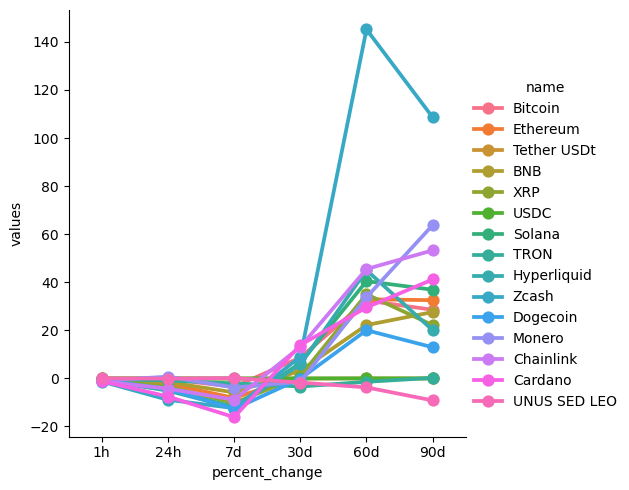

In [27]:
sns.catplot(x='percent_change', y='values', hue= 'name', data=df7, kind= 'point')

In [38]:
df10 = df[['name','quote.USD.price','timestamp']]
df10 = df10.query("name == 'Bitcoin'")
df10

,name,quote.USD.price,timestamp
0,Bitcoin,83137.86782,2026-10-13 14:13:56.542738


<Axes: xlabel='timestamp', ylabel='quote.USD.price'>

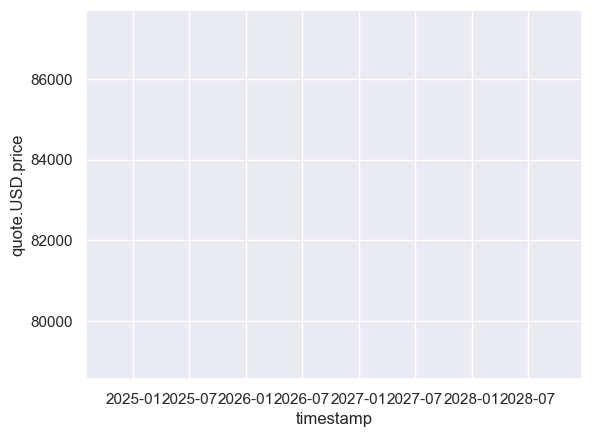

In [39]:
sns.set_theme(style='darkgrid')

sns.lineplot(x='timestamp', y='quote.USD.price', data =df10)